# 불량 기준 모델 비교

학습셋의 층화 5-fold 교차검증으로 전처리와 모델을 고른 뒤, 시험셋에서 한 번 평가한다.

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from analysis import load_data, make_xy, split_data, ProcessFeatures, save_eda, run_experiment

data_path = Path(os.environ.get("MANUFACTURING_DATA", ROOT / "data" / "labeled_data.csv"))
data = load_data(data_path)
output = ROOT / "results" / "current"


In [2]:
metrics = run_experiment(data, output, folds=5, seed=42)

none: defect F1=0.1350


standard: defect F1=0.1559


minmax: defect F1=0.1197


robust: defect F1=0.1782


D:\정유진-2025\2025-1\설명가능한 기계학습\팀 프로젝트\venv\Lib\site-packages\numpy\_core\_methods.py:194: RuntimeWarning: overflow encountered in multiply
  x = um.multiply(x, x, out=x)
D:\정유진-2025\2025-1\설명가능한 기계학습\팀 프로젝트\venv\Lib\site-packages\numpy\_core\_methods.py:205: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


D:\정유진-2025\2025-1\설명가능한 기계학습\팀 프로젝트\venv\Lib\site-packages\numpy\_core\_methods.py:194: RuntimeWarning: overflow encountered in multiply
  x = um.multiply(x, x, out=x)
D:\정유진-2025\2025-1\설명가능한 기계학습\팀 프로젝트\venv\Lib\site-packages\numpy\_core\_methods.py:205: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


... (12 outputs left out)

KNN: defect F1=0.2203


Naive Bayes: defect F1=0.0363


XGBoost: defect F1=0.4678


{
  "positive_class": "defect (N)",
  "seed": 42,
  "folds": 5,
  "rows": 7996,
  "train_rows": 6396,
  "test_rows": 1600,
  "defects_train": 57,
  "defects_test": 14,
  "best_scaling": "robust",
  "best_classifier": "Random forest",
  "accuracy": 0.991875,
  "precision": 0.5555555555555556,
  "recall": 0.35714285714285715,
  "f1": 0.43478260869565216,
  "roc_auc": 0.9655017114033507,
  "average_precision": 0.4329551497229671,
  "confusion_matrix": [
    [
      1582,
      4
    ],
    [
      9,
      5
    ]
  ]
}


In [3]:
display(pd.read_csv(output / 'preprocessing_cv.csv'))
display(pd.read_csv(output / 'classifier_cv.csv'))
display(pd.Series({key:metrics[key] for key in ['best_classifier','precision','recall','f1','defects_test']}))

,name,f1,f1_std,precision,precision_std,recall,recall_std,roc_auc,roc_auc_std
0,robust,0.178206,0.032003,0.102419,0.016994,0.696970,0.181122,0.952212,0.023788
1,quantile-normal,0.160838,0.044957,0.091959,0.024999,0.643939,0.209617,0.929389,0.045603
2,standard,0.155908,0.055792,0.087658,0.030831,0.712121,0.279380,0.942962,0.029464
3,none,0.135034,0.044573,0.075379,0.024087,0.656061,0.267440,0.941617,0.030521
4,yeo-johnson,0.133025,0.029491,0.074662,0.016482,0.610606,0.142424,0.942350,0.020694
5,quantile-uniform,0.126589,0.031953,0.071207,0.017321,0.574242,0.183352,0.919674,0.046180
6,minmax,0.119747,0.034244,0.068000,0.020073,0.507576,0.125675,0.903967,0.029547


,name,f1,f1_std,precision,precision_std,recall,recall_std,roc_auc,roc_auc_std
0,Random forest,0.492544,0.117777,0.675556,0.107761,0.398485,0.124353,0.949414,0.027115
1,XGBoost,0.467848,0.163453,0.618810,0.190536,0.380303,0.146147,0.937977,0.033583
2,Gradient boosting,0.410770,0.135207,0.431036,0.119716,0.413636,0.183802,0.954126,0.023354
3,Decision tree,0.383024,0.132266,0.355386,0.151577,0.433333,0.139312,0.712802,0.069615
4,KNN,0.220333,0.064722,0.140070,0.040556,0.519697,0.169778,0.806243,0.070413
5,Logistic regression,0.178206,0.032003,0.102419,0.016994,0.696970,0.181122,0.952212,0.023788
6,Linear SVM,0.171556,0.031144,0.098308,0.017017,0.680303,0.163074,0.948812,0.025309
7,Naive Bayes,0.036310,0.003627,0.018505,0.001871,0.963636,0.044536,0.832492,0.021791


best_classifier    Random forest
precision               0.555556
recall                  0.357143
f1                      0.434783
defects_test                  14
dtype: object

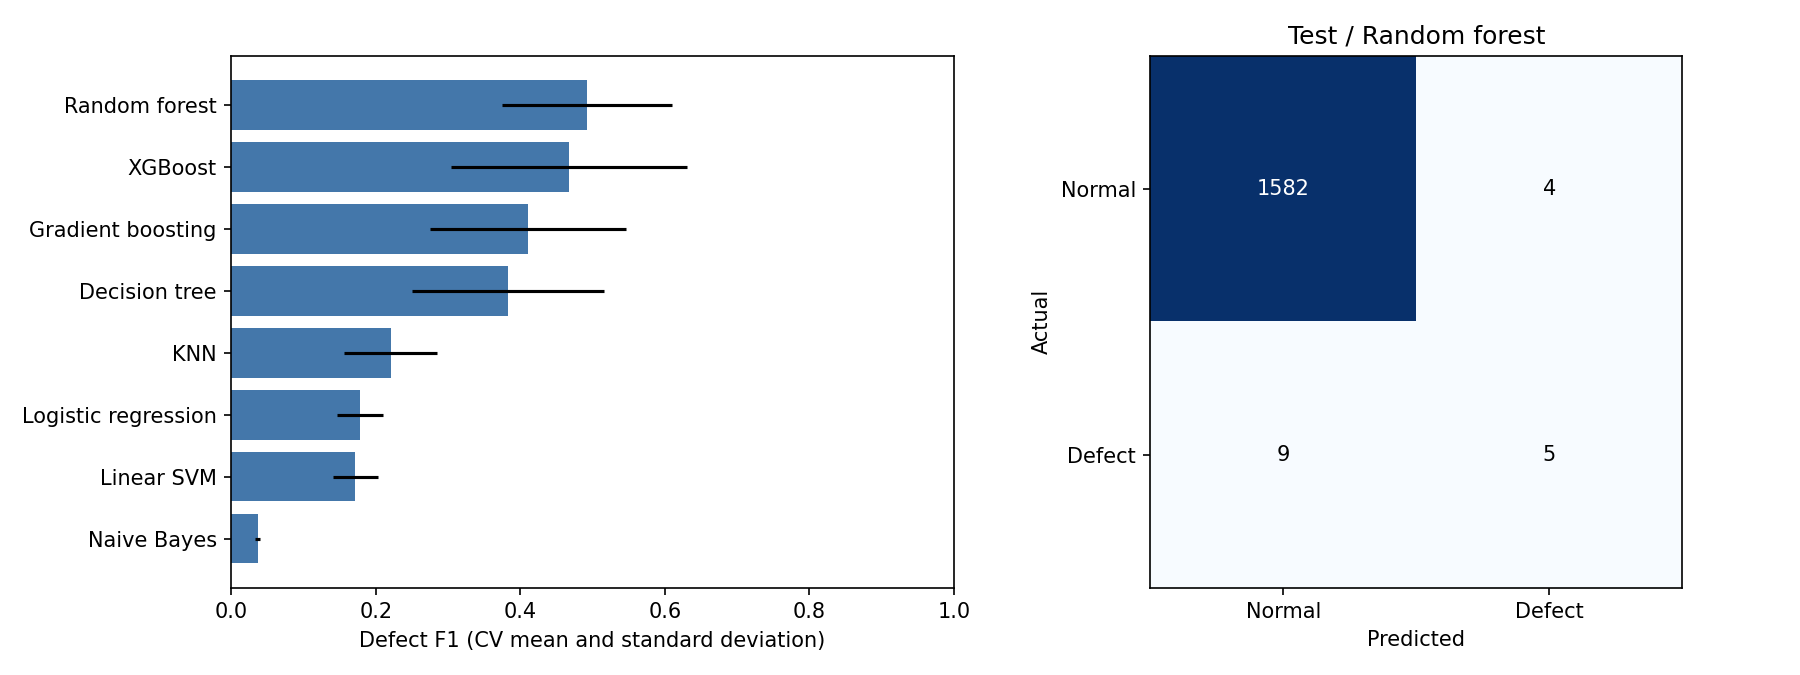

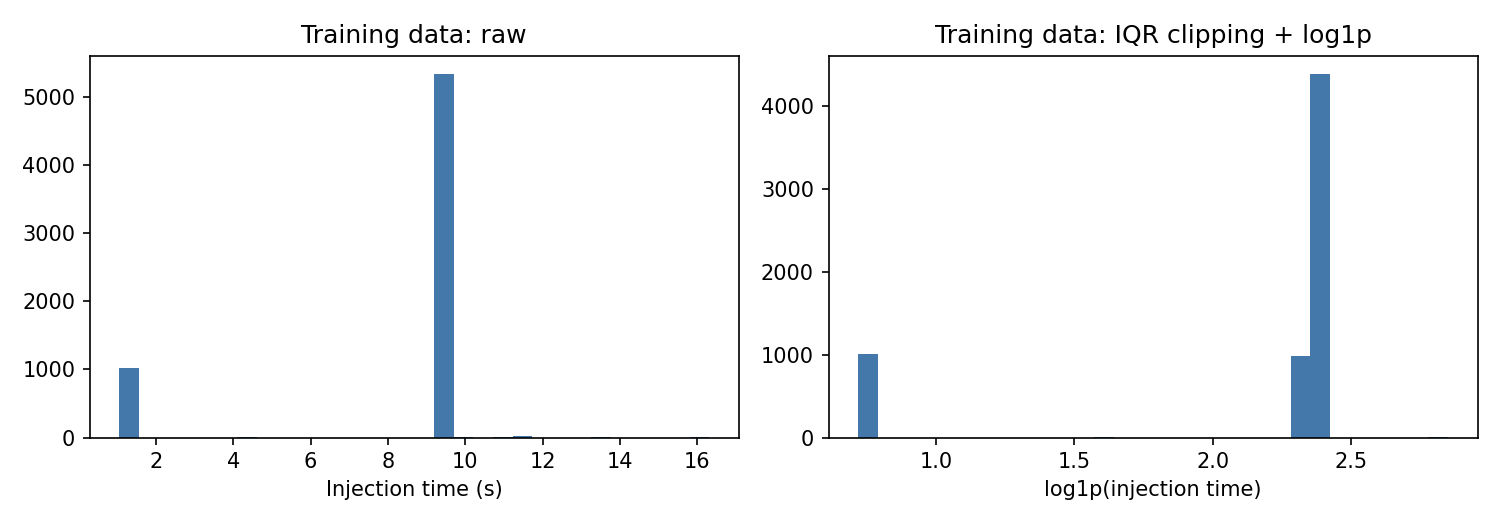

In [4]:
display(Image(filename=str(output / 'model_comparison.png')))
display(Image(filename=str(output / 'preprocessing.png')))

시험셋 불량 14개 중 탐지한 수와 놓친 수를 함께 본다. 현재 무작위 분할의 결과는 날짜나 설비가 다른 환경의 성능을 보장하지 않는다.